# Vehicle Predictive Maintenance – corrected pipeline

This notebook predicts whether a vehicle needs maintenance (`Need_Maintenance`, 1 = yes, 0 = no) from 50,000 vehicle records.

**What changed from the previous version** (following the examiner's feedback):

1. **The raw data is analysed first** (data understanding), before any record is changed or removed.
2. **The data is split into training and test sets before any cleaning.** The test set is locked away and never cleaned, scaled or inspected by any fitted step.
3. **Outlier detection (Isolation Forest) is fitted on the training set only, on the features only** (the target is never an input). The flagged records are inspected before deciding whether to remove them.
4. **All preprocessing (scaling, one-hot encoding) lives inside scikit-learn pipelines**, so it is fitted on training data only, also inside cross-validation.
5. **Decisions are made with stratified 5-fold cross-validation on the training set**, not on the test set. The test set is used once, at the end.

Pipeline: **load → understand the data → prepare features → stratified split → outlier analysis (training only) → model selection with CV → final test evaluation → explanation of results → cost analysis.**

## 1. Setup and loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, accuracy_score, f1_score, recall_score)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [2]:
# In Colab, mount Google Drive first:
# from google.colab import drive; drive.mount('/content/drive')
# file_path = '/content/drive/MyDrive/data Mining/Source500/3 Datasets/vehicle_maintenance_data.csv'
file_path = 'vehicle_maintenance_data.csv'

df = pd.read_csv(file_path)
print(df.shape)
df.head()

(50000, 20)


,Vehicle_Model,Mileage,Maintenance_History,Reported_Issues,Vehicle_Age,Fuel_Type,Transmission_Type,Engine_Size,Odometer_Reading,Last_Service_Date,Warranty_Expiry_Date,Owner_Type,Insurance_Premium,Service_History,Accident_History,Fuel_Efficiency,Tire_Condition,Brake_Condition,Battery_Status,Need_Maintenance
0,Truck,58765,Good,0,4,Electric,Automatic,2000,28524,2023-11-23,2025-06-24,Second,20782,6,3,13.622204,New,New,Weak,1
1,Van,60353,Average,1,7,Electric,Automatic,2500,133630,2023-09-21,2025-06-04,Second,23489,7,0,13.625307,New,New,Weak,1
2,Bus,68072,Poor,0,2,Electric,Automatic,1500,34022,2023-06-27,2025-04-27,First,17979,7,0,14.306302,New,Good,Weak,1
3,Bus,60849,Average,4,5,Petrol,Automatic,2500,81636,2023-08-24,2025-11-05,Second,6220,7,3,18.709467,New,Worn Out,New,1
4,Bus,45742,Poor,5,1,Petrol,Manual,2000,97162,2023-05-25,2025-09-14,Third,16446,6,2,16.977482,Good,Good,Weak,1


## 2. Data understanding (raw data, before any change)

Before preparing or cleaning anything, we look at the raw data: types, missing values, duplicates, class balance, distributions, data quality and how each attribute relates to the target.

In [3]:
TARGET = 'Need_Maintenance'
num_cols = df.select_dtypes(include='number').columns.drop(TARGET).tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
print('Numeric attributes    :', num_cols)
print('Categorical attributes:', cat_cols)
print()
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))

Numeric attributes    : ['Mileage', 'Reported_Issues', 'Vehicle_Age', 'Engine_Size', 'Odometer_Reading', 'Insurance_Premium', 'Service_History', 'Accident_History', 'Fuel_Efficiency']
Categorical attributes: ['Vehicle_Model', 'Maintenance_History', 'Fuel_Type', 'Transmission_Type', 'Last_Service_Date', 'Warranty_Expiry_Date', 'Owner_Type', 'Tire_Condition', 'Brake_Condition', 'Battery_Status']

Missing values: 0
Duplicate rows: 0


                  count  share
Need_Maintenance              
0                  9502   0.19
1                 40498   0.81


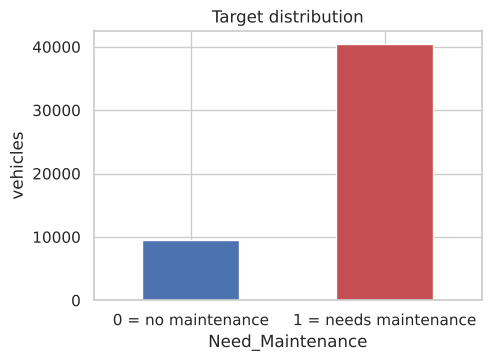

In [4]:
# Class balance
counts = df[TARGET].value_counts().sort_index()
print(pd.DataFrame({'count': counts, 'share': (counts / len(df)).round(3)}))

ax = counts.plot(kind='bar', color=['#4C72B0', '#C44E52'], figsize=(5, 3.5))
ax.set_xticklabels(['0 = no maintenance', '1 = needs maintenance'], rotation=0)
ax.set_ylabel('vehicles'); ax.set_title('Target distribution')
plt.show()

The classes are **imbalanced: about 81% of vehicles need maintenance and 19% do not.** Accuracy alone is therefore misleading (always predicting "1" already gives 81%), so we also report recall, F1 and ROC-AUC, use a **stratified** split, and give Logistic Regression balanced class weights.

,count,mean,std,min,25%,50%,75%,max
Mileage,50000.0,54931.23,14401.91,30001.0,42471.50,54810.00,67391.50,80000.0
Reported_Issues,50000.0,2.50,1.71,0.0,1.00,2.00,4.00,5.0
Vehicle_Age,50000.0,5.49,2.88,1.0,3.00,5.00,8.00,10.0
Engine_Size,50000.0,1556.29,627.68,800.0,1000.00,1500.00,2000.00,2500.0
Odometer_Reading,50000.0,75551.19,43088.11,1001.0,38009.00,75598.50,112999.50,149999.0
Insurance_Premium,50000.0,17465.34,7223.39,5000.0,11189.75,17477.50,23692.00,30000.0
Service_History,50000.0,5.52,2.87,1.0,3.00,6.00,8.00,10.0
Accident_History,50000.0,1.50,1.12,0.0,0.00,2.00,3.00,3.0
Fuel_Efficiency,50000.0,14.99,2.89,10.0,12.49,14.99,17.47,20.0


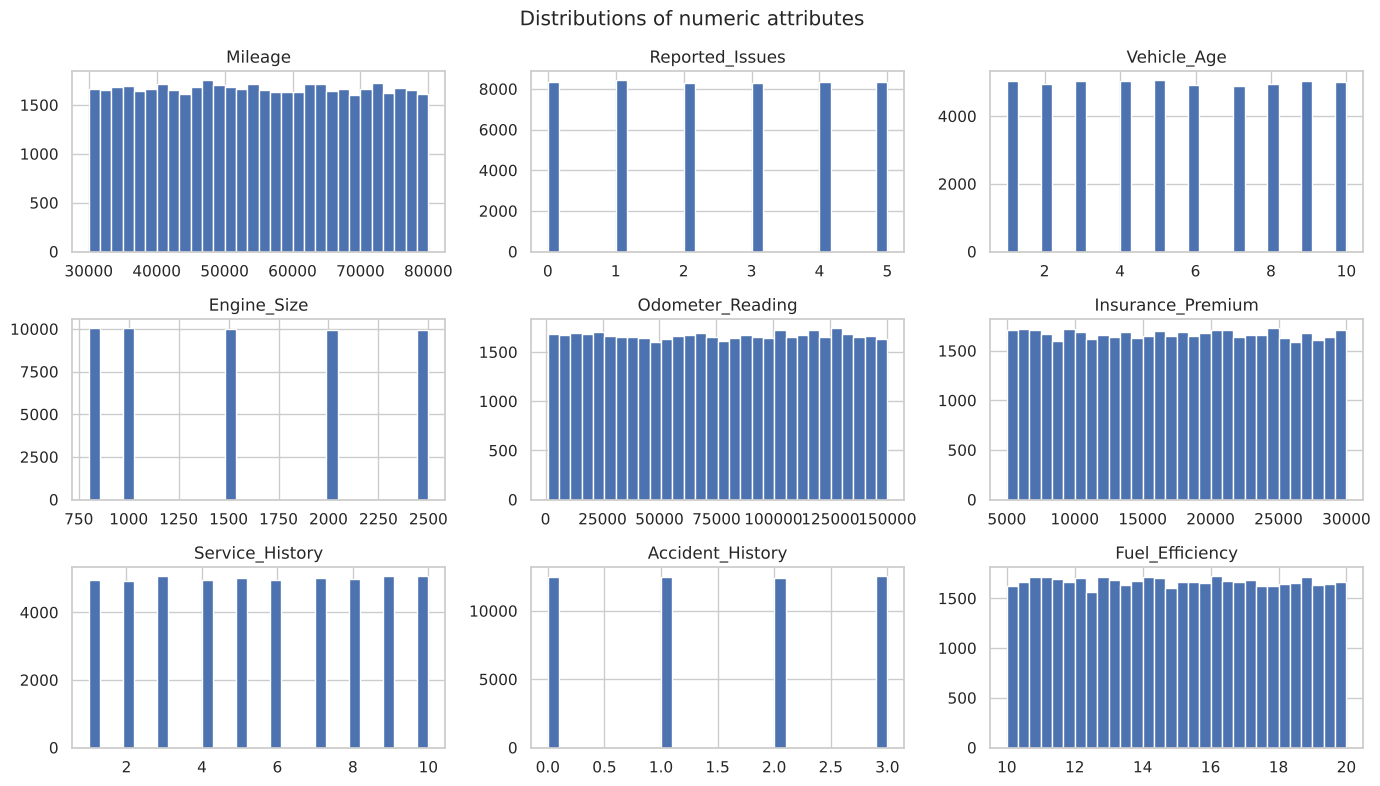

In [5]:
# Numeric attributes: summary statistics and distributions
display(df[num_cols].describe().T.round(2))

df[num_cols].hist(bins=30, figsize=(14, 8), layout=(3, 3), color='#4C72B0')
plt.suptitle('Distributions of numeric attributes'); plt.tight_layout(); plt.show()

In [6]:
# Categorical attributes: number of distinct values and frequencies
for c in cat_cols:
    vc = df[c].value_counts()
    print(f'{c:22s} {df[c].nunique():4d} values   e.g. { {k: int(v) for k, v in vc.head(6).items()} }')

Vehicle_Model             6 values   e.g. {'Bus': 8414, 'Van': 8400, 'SUV': 8360, 'Truck': 8328, 'Motorcycle': 8295, 'Car': 8203}
Maintenance_History       3 values   e.g. {'Average': 16724, 'Good': 16712, 'Poor': 16564}
Fuel_Type                 3 values   e.g. {'Diesel': 16738, 'Petrol': 16680, 'Electric': 16582}
Transmission_Type         2 values   e.g. {'Manual': 25009, 'Automatic': 24991}
Last_Service_Date       336 values   e.g. {'2023-11-25': 182, '2023-08-08': 181, '2023-11-14': 179, '2023-10-03': 177, '2023-10-20': 175, '2023-11-20': 175}
Warranty_Expiry_Date    701 values   e.g. {'2024-09-16': 101, '2025-05-13': 99, '2025-06-06': 98, '2024-05-17': 95, '2024-07-31': 94, '2024-08-30': 93}
Owner_Type                3 values   e.g. {'Second': 16875, 'Third': 16630, 'First': 16495}
Tire_Condition            3 values   e.g. {'New': 16825, 'Worn Out': 16622, 'Good': 16553}
Brake_Condition           3 values   e.g. {'Worn Out': 16685, 'New': 16668, 'Good': 16647}
Battery_Status      

**Observations.** There are no missing values and no duplicates. Almost every attribute is close to **uniformly distributed** (e.g. each vehicle model ≈ 8,300 records, each fuel type ≈ 16,600, ages 1–10 evenly spread). The two date columns have 336 and 701 distinct values, so they cannot be used as categories; we turn them into numeric durations (Section 3).

In [7]:
# Data-quality check: values that are physically inconsistent
inconsistent = df['Mileage'] > df['Odometer_Reading']
print(f'Mileage greater than odometer reading: {inconsistent.sum():,} rows ({inconsistent.mean():.1%})')

dates_service = pd.to_datetime(df['Last_Service_Date'])
dates_warranty = pd.to_datetime(df['Warranty_Expiry_Date'])
print('Last service dates   :', dates_service.min().date(), 'to', dates_service.max().date())
print('Warranty expiry dates:', dates_warranty.min().date(), 'to', dates_warranty.max().date())

Mileage greater than odometer reading: 18,096 rows (36.2%)
Last service dates   : 2023-03-30 to 2024-02-28
Warranty expiry dates: 2024-04-28 to 2026-03-29


More than a third of the records have a mileage higher than the odometer reading, which is physically impossible. Because it affects 36% of the data, uniformly, it is not a handful of erroneous records that could be removed: it indicates that the columns were **generated independently**. Together with the uniform distributions, this suggests the dataset is **synthetic**. We keep these rows (removing 36% of the data is not an option) and note this as a limitation.

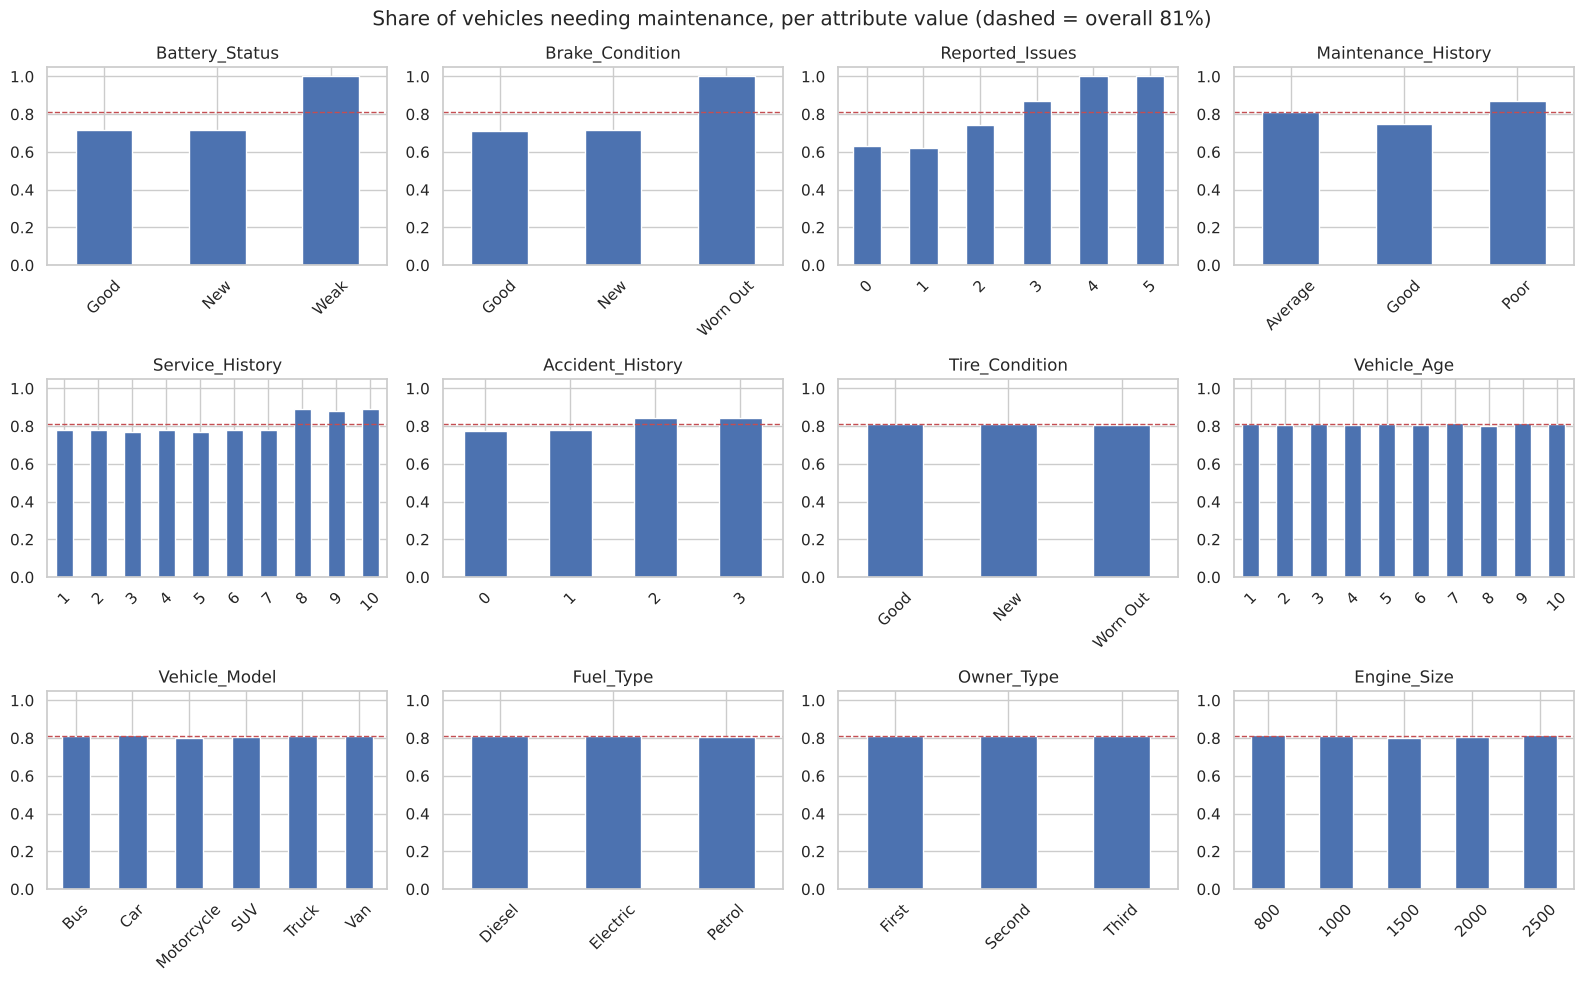

In [8]:
# How does each attribute relate to the target? (share of vehicles needing maintenance per value)
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
show = ['Battery_Status', 'Brake_Condition', 'Reported_Issues', 'Maintenance_History',
        'Service_History', 'Accident_History', 'Tire_Condition', 'Vehicle_Age',
        'Vehicle_Model', 'Fuel_Type', 'Owner_Type', 'Engine_Size']
for ax, c in zip(axes.ravel(), show):
    rate = df.groupby(c)[TARGET].mean()
    rate.plot(kind='bar', ax=ax, color='#4C72B0')
    ax.axhline(df[TARGET].mean(), color='#C44E52', ls='--', lw=1)
    ax.set_ylim(0, 1.05); ax.set_title(c); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=45)
plt.suptitle('Share of vehicles needing maintenance, per attribute value (dashed = overall 81%)')
plt.tight_layout(); plt.show()

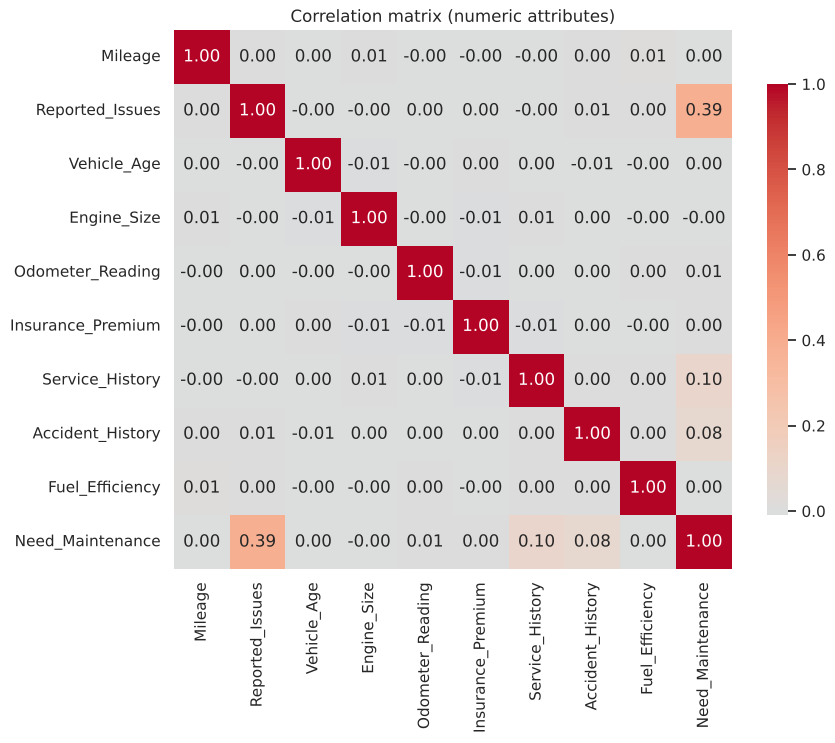

Reported_Issues      0.389
Service_History      0.104
Accident_History     0.081
Odometer_Reading     0.008
Insurance_Premium    0.005
Fuel_Efficiency      0.002
Vehicle_Age          0.001
Mileage              0.001
Engine_Size         -0.000
Name: Need_Maintenance, dtype: float64


In [9]:
# Correlation of numeric attributes with the target
corr = df[num_cols + [TARGET]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar_kws={'shrink': .8})
plt.title('Correlation matrix (numeric attributes)'); plt.show()
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

**What drives the target.** Six attributes clearly matter:

- **Battery_Status = Weak → 100%** of these vehicles need maintenance.
- **Brake_Condition = Worn Out → 100%**.
- **Reported_Issues ≥ 4 → 100%**; the share also rises from 2 to 3 issues.
- **Maintenance_History** (Poor > Average > Good), **Service_History ≥ 8** and **Accident_History ≥ 2** raise the share.

All other attributes (mileage, age, odometer, model, fuel, engine size, owner, tires, insurance, fuel efficiency) have practically no relation to the target (correlations ≈ 0). No attribute is a copy of the target (highest correlation: Reported_Issues, 0.39).

In [10]:
# Is the label a deterministic function of these six attributes?
drivers = ['Battery_Status', 'Brake_Condition', 'Reported_Issues',
           'Maintenance_History', 'Service_History', 'Accident_History']
groups = df.groupby(drivers)[TARGET].agg(['mean', 'size'])
mixed = ((groups['mean'] > 0) & (groups['mean'] < 1)).sum()
print(f'Distinct combinations of the 6 attributes: {len(groups):,}')
print(f'Combinations containing BOTH labels      : {mixed}')

Distinct combinations of the 6 attributes: 6,479
Combinations containing BOTH labels      : 0


**Key finding of the data understanding phase:** every one of the 6,479 combinations of these six attributes always has the same label. The target is therefore a **deterministic rule** of six attributes, with no noise. A model that can represent if-then rules (decision trees, Random Forest) can in principle reach 100% accuracy on this data, while a linear model cannot. We keep this in mind when interpreting the results.

## 3. Feature preparation (no fitting on the data)

Only deterministic transformations happen here: nothing is learned from the data, so they can safely be applied before the split.

- The two dates are converted to durations relative to a **fixed reference date (2024-03-01)**, chosen just after the latest service date seen in Section 2: `Days_Since_Service` and `Days_To_Warranty_End`. The raw date strings are dropped.
- Categorical attributes stay as text; they are **one-hot encoded inside the model pipelines** (Section 6), so the encoder is fitted on training data only.

In [11]:
REFERENCE_DATE = pd.Timestamp('2024-03-01')

data = df.copy()
data['Days_Since_Service']   = (REFERENCE_DATE - pd.to_datetime(data['Last_Service_Date'])).dt.days
data['Days_To_Warranty_End'] = (pd.to_datetime(data['Warranty_Expiry_Date']) - REFERENCE_DATE).dt.days
data = data.drop(columns=['Last_Service_Date', 'Warranty_Expiry_Date'])

X = data.drop(columns=[TARGET])
y = data[TARGET]
num_features = X.select_dtypes(include='number').columns.tolist()
cat_features = X.select_dtypes(exclude='number').columns.tolist()
print('Numeric features    :', num_features)
print('Categorical features:', cat_features)

Numeric features    : ['Mileage', 'Reported_Issues', 'Vehicle_Age', 'Engine_Size', 'Odometer_Reading', 'Insurance_Premium', 'Service_History', 'Accident_History', 'Fuel_Efficiency', 'Days_Since_Service', 'Days_To_Warranty_End']
Categorical features: ['Vehicle_Model', 'Maintenance_History', 'Fuel_Type', 'Transmission_Type', 'Owner_Type', 'Tire_Condition', 'Brake_Condition', 'Battery_Status']


## 4. Train/test split – before any cleaning

We split **first**, with stratification so both sets keep the 81/19 class ratio. From here on the **test set is locked**: no scaling, outlier detection or model selection ever looks at it. It plays the role of new, unseen vehicles.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f'Training set: {len(X_train):,} rows, share needing maintenance = {y_train.mean():.3f}')
print(f'Test set    : {len(X_test):,} rows, share needing maintenance = {y_test.mean():.3f}')

Training set: 40,000 rows, share needing maintenance = 0.810
Test set    : 10,000 rows, share needing maintenance = 0.810


## 5. Outlier analysis with Isolation Forest (training set only)

Isolation Forest is unsupervised: it builds random trees that split the data on random features and random cut values. Records that are isolated after few splits (short average path length) get a high anomaly score. `contamination=0.01` sets the threshold so that the 1% most isolated records are flagged.

Corrections compared to the previous version:

- fitted on the **training set only** (the test set is not touched);
- the **target is not an input**, only the features;
- features are scaled and one-hot encoded inside the pipeline;
- the flagged records are **inspected before deciding** whether to remove them.

In [13]:
def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)])

iso = Pipeline([
    ('prep', make_preprocessor()),
    ('iforest', IsolationForest(n_estimators=200, contamination=0.01,
                                random_state=RANDOM_STATE, n_jobs=-1))])
iso.fit(X_train)                       # features only, training set only

train_flag = iso.predict(X_train)      # 1 = normal, -1 = anomaly
train_score = iso.decision_function(X_train)
is_anomaly = train_flag == -1
print(f'Flagged as anomalies: {is_anomaly.sum()} of {len(X_train):,} training records ({is_anomaly.mean():.1%})')

Flagged as anomalies: 400 of 40,000 training records (1.0%)


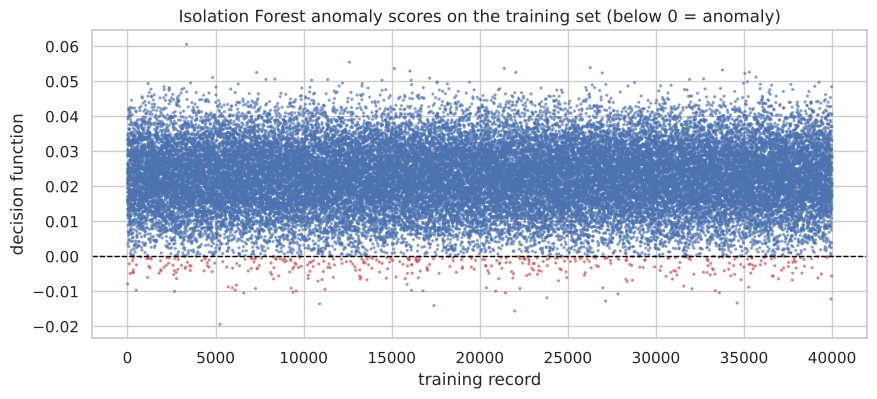

In [14]:
plt.figure(figsize=(10, 4))
plt.scatter(np.arange(len(train_score)), train_score, s=2,
            c=np.where(is_anomaly, '#C44E52', '#4C72B0'), alpha=.5)
plt.axhline(0, color='black', ls='--', lw=1)
plt.title('Isolation Forest anomaly scores on the training set (below 0 = anomaly)')
plt.xlabel('training record'); plt.ylabel('decision function'); plt.show()

In [15]:
# Inspect the flagged records: what makes them different?
flagged, normal = X_train[is_anomaly], X_train[~is_anomaly]
comparison = pd.DataFrame({'normal (mean)': normal[num_features].mean(),
                           'flagged (mean)': flagged[num_features].mean()}).round(1)
display(comparison)
print('Share needing maintenance: normal =', round(y_train[~is_anomaly].mean(), 3),
      '| flagged =', round(y_train[is_anomaly].mean(), 3))
print('Mileage > odometer: normal =', round((normal.Mileage > normal.Odometer_Reading).mean(), 3),
      '| flagged =', round((flagged.Mileage > flagged.Odometer_Reading).mean(), 3))
flagged.head(10)

,normal (mean),flagged (mean)
Mileage,54909.0,56874.2
Reported_Issues,2.5,2.0
Vehicle_Age,5.5,5.5
Engine_Size,1551.3,1800.0
Odometer_Reading,75399.0,78693.8
Insurance_Premium,17496.0,16814.2
Service_History,5.5,5.0
Accident_History,1.5,1.6
Fuel_Efficiency,15.0,13.9
Days_Since_Service,169.6,176.3


Share needing maintenance: normal = 0.811 | flagged = 0.752
Mileage > odometer: normal = 0.363 | flagged = 0.402


,Vehicle_Model,Mileage,Maintenance_History,Reported_Issues,Vehicle_Age,Fuel_Type,Transmission_Type,Engine_Size,Odometer_Reading,Owner_Type,Insurance_Premium,Service_History,Accident_History,Fuel_Efficiency,Tire_Condition,Brake_Condition,Battery_Status,Days_Since_Service,Days_To_Warranty_End
42379,Truck,50890,Average,0,1,Petrol,Manual,800,44962,Second,5481,3,0,10.747863,New,New,New,289,174
18170,Van,42793,Average,4,1,Petrol,Manual,1000,125300,Second,29997,1,3,19.614395,Worn Out,Worn Out,New,334,177
1331,SUV,69245,Poor,5,10,Petrol,Manual,2000,16182,First,5226,10,3,10.425531,Good,Good,Weak,228,254
15571,SUV,47617,Average,0,1,Diesel,Automatic,800,99018,First,24646,1,3,14.562353,Worn Out,Worn Out,New,316,665
45823,Van,34607,Poor,5,4,Electric,Automatic,2500,17033,Second,27449,10,3,17.871908,Worn Out,Good,Good,308,712
10935,Truck,77988,Good,5,2,Electric,Automatic,800,10686,Second,23920,1,0,15.677737,Worn Out,Good,Good,156,722
1085,Van,77589,Poor,0,1,Electric,Automatic,2500,13590,First,7375,5,0,11.127432,Good,New,Weak,278,168
42759,Bus,70090,Poor,1,10,Petrol,Manual,2500,67345,Third,9300,2,3,10.197154,Worn Out,Worn Out,Good,273,75
38292,Car,59921,Poor,0,1,Electric,Automatic,2000,14486,Third,26209,2,3,18.345762,Worn Out,Good,New,5,343
3291,Car,70239,Average,3,10,Electric,Automatic,2500,13017,Second,26268,2,0,10.301741,Worn Out,Worn Out,New,20,98


**Interpretation.** On average the flagged records differ only slightly from the rest, and every individual value lies inside the normal range of its attribute: none is an impossible or erroneous value that normal records do not also have (e.g. mileage > odometer occurs in 36% of normal records too). What makes them unusual is the **combination** of values, for example a one-year-old vehicle with a very high odometer reading and a large engine. With uniformly generated (synthetic) data, these are rare but valid combinations, not data errors. Their share of vehicles needing maintenance (≈75%) is close to the overall 81%. Whether removing them helps is therefore an empirical question, which we answer with cross-validation on the training set in the next section, never with the test set.

## 6. Models and model selection (cross-validation on the training set)

- **Logistic Regression** (baseline): linear model, `class_weight='balanced'` because of the 81/19 imbalance, scaled numeric features and one-hot encoded categories.
- **Random Forest** (main model): 100 trees, each trained on a bootstrap sample with a random subset of features per split; the trees vote.

Both are full pipelines (preprocessing + model), so scaling and encoding are re-fitted inside every fold.

We compare each model **with and without outlier removal**, using **stratified 5-fold cross-validation on the training set**. In the "with removal" variant, the Isolation Forest is fitted inside each fold on that fold's training part only, and the validation part is never cleaned.

In [16]:
def make_logreg():
    return Pipeline([('prep', make_preprocessor()),
                     ('model', LogisticRegression(class_weight='balanced', max_iter=2000,
                                                  random_state=RANDOM_STATE))])

def make_forest():
    return Pipeline([('prep', make_preprocessor()),
                     ('model', RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE,
                                                      n_jobs=-1))])

def remove_outliers(X_part, y_part):
    # Fit Isolation Forest on this training part only (features only) and drop the flagged 1%.
    det = Pipeline([('prep', make_preprocessor()),
                    ('iforest', IsolationForest(n_estimators=200, contamination=0.01,
                                                random_state=RANDOM_STATE, n_jobs=-1))])
    keep = det.fit(X_part).predict(X_part) == 1
    return X_part[keep], y_part[keep]

def cv_scores(make_model, with_removal, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for tr, va in skf.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr], y_train.iloc[tr]
        X_va, y_va = X_train.iloc[va], y_train.iloc[va]      # validation part is never cleaned
        if with_removal:
            X_tr, y_tr = remove_outliers(X_tr, y_tr)
        m = make_model().fit(X_tr, y_tr)
        p = m.predict(X_va); proba = m.predict_proba(X_va)[:, 1]
        rows.append({'accuracy': accuracy_score(y_va, p), 'recall (1)': recall_score(y_va, p),
                     'recall (0)': recall_score(y_va, p, pos_label=0),
                     'F1 (1)': f1_score(y_va, p), 'ROC-AUC': roc_auc_score(y_va, proba)})
    return pd.DataFrame(rows).agg(['mean', 'std'])

results = {}
for name, maker in [('Logistic Regression', make_logreg), ('Random Forest', make_forest)]:
    for removal in [False, True]:
        res = cv_scores(maker, removal)
        results[(name, 'with outlier removal' if removal else 'no outlier removal')] = res.loc['mean']
        print(f'{name:20s} | {"with" if removal else "no  "} outlier removal | ' +
              ' '.join(f'{k} {res.loc["mean", k]:.4f}±{res.loc["std", k]:.4f}' for k in res.columns))

cv_table = pd.DataFrame(results).T.round(4)
cv_table

Logistic Regression  | no   outlier removal | accuracy 0.9551±0.0043 recall (1) 0.9464±0.0055 recall (0) 0.9918±0.0027 F1 (1) 0.9715±0.0028 ROC-AUC 0.9868±0.0014


Logistic Regression  | with outlier removal | accuracy 0.9550±0.0043 recall (1) 0.9462±0.0055 recall (0) 0.9929±0.0025 F1 (1) 0.9715±0.0028 ROC-AUC 0.9868±0.0014


Random Forest        | no   outlier removal | accuracy 1.0000±0.0000 recall (1) 1.0000±0.0000 recall (0) 1.0000±0.0000 F1 (1) 1.0000±0.0000 ROC-AUC 1.0000±0.0000


Random Forest        | with outlier removal | accuracy 1.0000±0.0000 recall (1) 1.0000±0.0000 recall (0) 1.0000±0.0000 F1 (1) 1.0000±0.0000 ROC-AUC 1.0000±0.0000


accuracy  recall (1)  recall (0)  \
Logistic Regression no outlier removal      0.9551      0.9464      0.9918   
                    with outlier removal    0.9550      0.9462      0.9929   
Random Forest       no outlier removal      1.0000      1.0000      1.0000   
                    with outlier removal    1.0000      1.0000      1.0000   

                                          F1 (1)  ROC-AUC  
Logistic Regression no outlier removal    0.9715   0.9868  
                    with outlier removal  0.9715   0.9868  
Random Forest       no outlier removal    1.0000   1.0000  
                    with outlier removal  1.0000   1.0000

**Decision.** Removing the 1% Isolation Forest outliers does not improve cross-validated performance for either model: the differences are within the fold-to-fold variation. Because the flagged records are valid (if unusual) vehicles and removing them throws away data without a measurable benefit, **the final models are trained on the full training set, without outlier removal.** Isolation Forest remains useful as a monitoring tool: in deployment it can flag unusual incoming vehicles for a human check.

## 7. Final evaluation on the untouched test set

The two models are trained once on the full training set (40,000 records) and evaluated once on the test set (10,000 records), which has not been used for any decision so far.

In [17]:
logreg = make_logreg().fit(X_train, y_train)
forest = make_forest().fit(X_train, y_train)

summary = []
for name, model in [('Logistic Regression', logreg), ('Random Forest', forest)]:
    pred = model.predict(X_test); proba = model.predict_proba(X_test)[:, 1]
    print(f'===== {name} =====')
    print(classification_report(y_test, pred, digits=3))
    summary.append({'model': name, 'accuracy': accuracy_score(y_test, pred),
                    'precision (1)': classification_report(y_test, pred, output_dict=True)['1']['precision'],
                    'recall (1)': recall_score(y_test, pred), 'recall (0)': recall_score(y_test, pred, pos_label=0),
                    'F1 (1)': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, proba)})
test_table = pd.DataFrame(summary).set_index('model').round(4)
test_table

===== Logistic Regression =====
              precision    recall  f1-score   support

           0      0.828     0.996     0.904      1900
           1      0.999     0.951     0.975      8100

    accuracy                          0.960     10000
   macro avg      0.914     0.974     0.940     10000
weighted avg      0.967     0.960     0.961     10000

===== Random Forest =====


              precision    recall  f1-score   support

           0      1.000     1.000     1.000      1900
           1      1.000     1.000     1.000      8100

    accuracy                          1.000     10000
   macro avg      1.000     1.000     1.000     10000
weighted avg      1.000     1.000     1.000     10000



,accuracy,precision (1),recall (1),recall (0),F1 (1),ROC-AUC
model,,,,,,
Logistic Regression,0.96,0.9991,0.9515,0.9963,0.9747,0.9878
Random Forest,1.00,1.0000,1.0000,1.0000,1.0000,1.0000


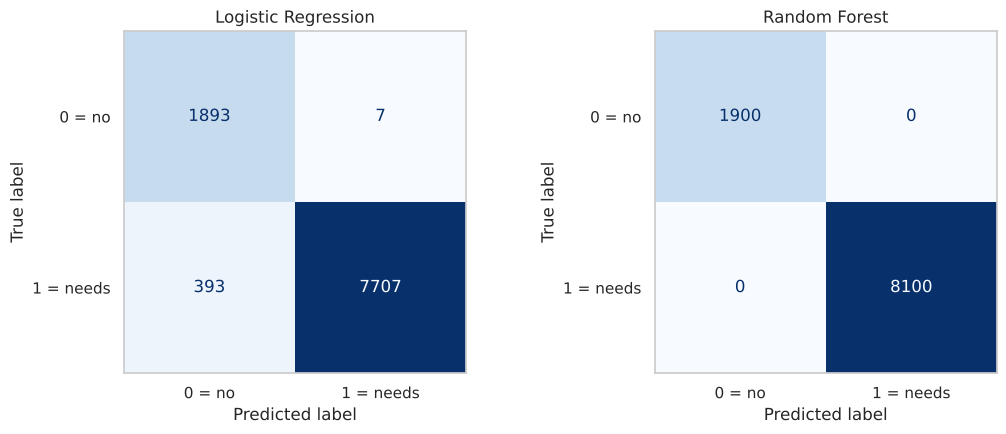

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, [('Logistic Regression', logreg), ('Random Forest', forest)]):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap='Blues', colorbar=False,
                                          display_labels=['0 = no', '1 = needs'])
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.show()

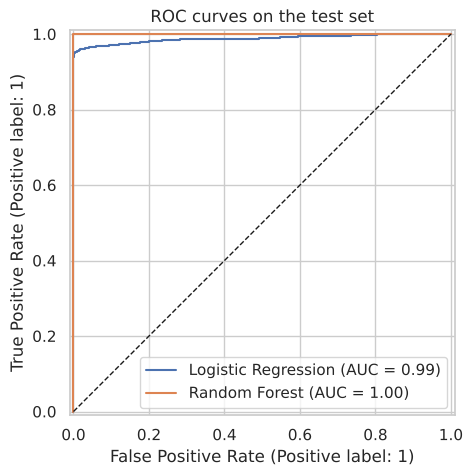

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(logreg, X_test, y_test, ax=ax, name='Logistic Regression')
RocCurveDisplay.from_estimator(forest, X_test, y_test, ax=ax, name='Random Forest')
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_title('ROC curves on the test set'); plt.show()

**Results on the test set.**

- **Random Forest** classifies all 10,000 test vehicles correctly (accuracy 1.00, ROC-AUC 1.00, no false negatives and no false positives).
- **Logistic Regression** reaches 96% accuracy and ROC-AUC 0.988. Its main error is missing vehicles that need maintenance (false negatives), while it almost never raises a false alarm.
- Compared with the previous version (85%), Logistic Regression improves a lot because the categories are now **one-hot encoded** and the numeric features **scaled**: with integer codes a linear model has to treat categories such as "Weak / New / Good" as an ordered quantity; with one-hot encoding each value gets its own weight. This also matches the WEKA result for Logistic Regression (≈96%), since WEKA one-hot encodes nominal attributes automatically.

## 8. Overfitting check: learning curves (training set, 5-fold CV)

Logistic Regression CV accuracy by size: {3200: 0.9518, 10400: 0.954, 17600: 0.9538, 24800: 0.9544, 32000: 0.9551}


Random Forest CV accuracy by size: {3200: 0.9948, 10400: 0.9997, 17600: 1.0, 24800: 1.0, 32000: 1.0}


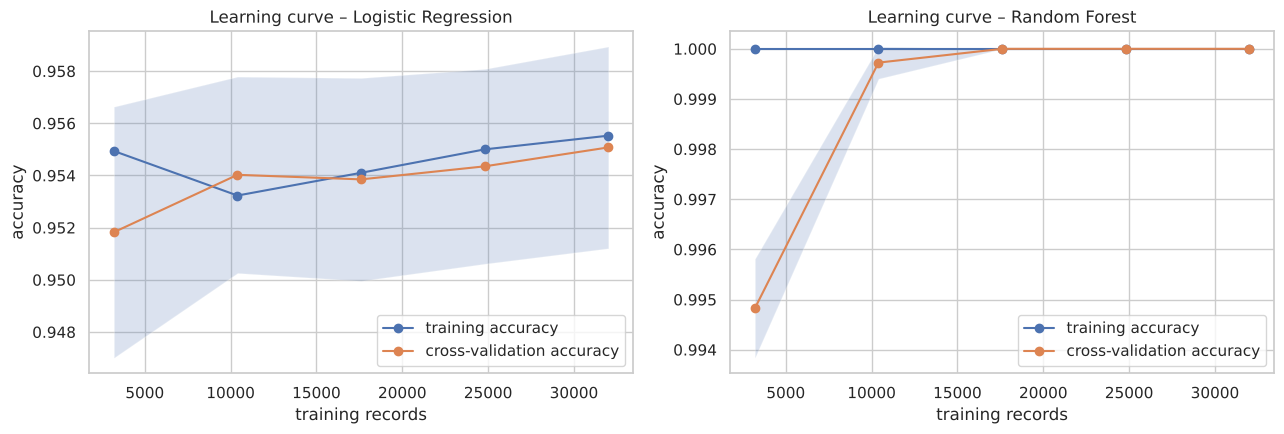

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for ax, (name, maker) in zip(axes, [('Logistic Regression', make_logreg), ('Random Forest', make_forest)]):
    sizes, tr, va = learning_curve(maker(), X_train, y_train, cv=cv5, scoring='accuracy',
                                   train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1)
    ax.plot(sizes, tr.mean(1), 'o-', label='training accuracy')
    ax.plot(sizes, va.mean(1), 'o-', label='cross-validation accuracy')
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.2)
    ax.set_title(f'Learning curve – {name}'); ax.set_xlabel('training records'); ax.set_ylabel('accuracy')
    ax.legend(loc='lower right')
    print(name, 'CV accuracy by size:', {int(n): round(float(a), 4) for n, a in zip(sizes, va.mean(1))})
plt.tight_layout(); plt.show()

- **Logistic Regression:** training and validation accuracy are close to each other and flat: more data does not help. This is **underfitting (high bias)**: a linear boundary cannot represent the rule behind the label.
- **Random Forest:** validation accuracy rises with more data and meets the training accuracy. There is no persistent gap between the curves, so the model is **not overfitting**: it generalises to records it has not seen.

## 9. Why can Random Forest be (almost) perfect? Feature importance and the rule behind the label

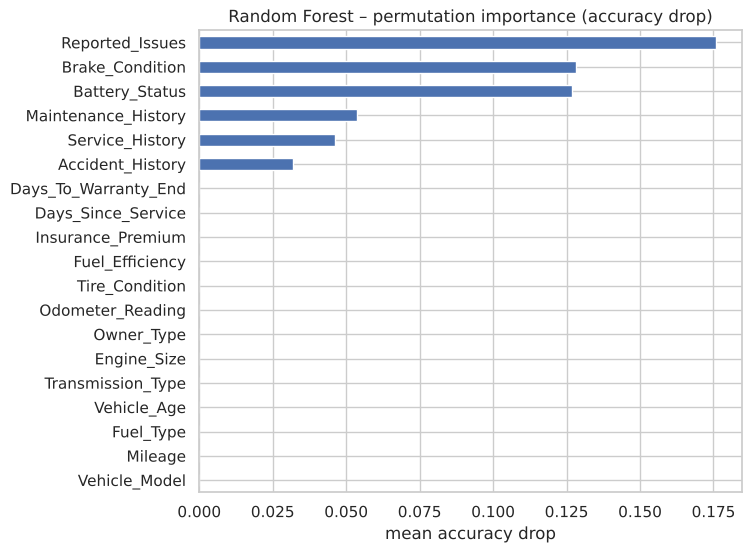

Reported_Issues        0.1758
Brake_Condition        0.1284
Battery_Status         0.1268
Maintenance_History    0.0538
Service_History        0.0462
Accident_History       0.0320
Vehicle_Model          0.0000
Fuel_Type              0.0000
dtype: float64


In [21]:
# Permutation importance on the test set: how much does accuracy drop when one attribute is shuffled?
perm = permutation_importance(forest, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                              scoring='accuracy', n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance.plot(kind='barh', figsize=(7, 6), color='#4C72B0')
plt.title('Random Forest – permutation importance (accuracy drop)'); plt.xlabel('mean accuracy drop'); plt.show()
print(importance.sort_values(ascending=False).round(4).head(8))

Decision tree on the 6 driver attributes, max_depth=3: test accuracy = 0.9272
Decision tree on the 6 driver attributes, max_depth=5: test accuracy = 0.9782
Decision tree on the 6 driver attributes, max_depth=8: test accuracy = 1.0000
Decision tree on the 6 driver attributes, max_depth=None: test accuracy = 1.0000


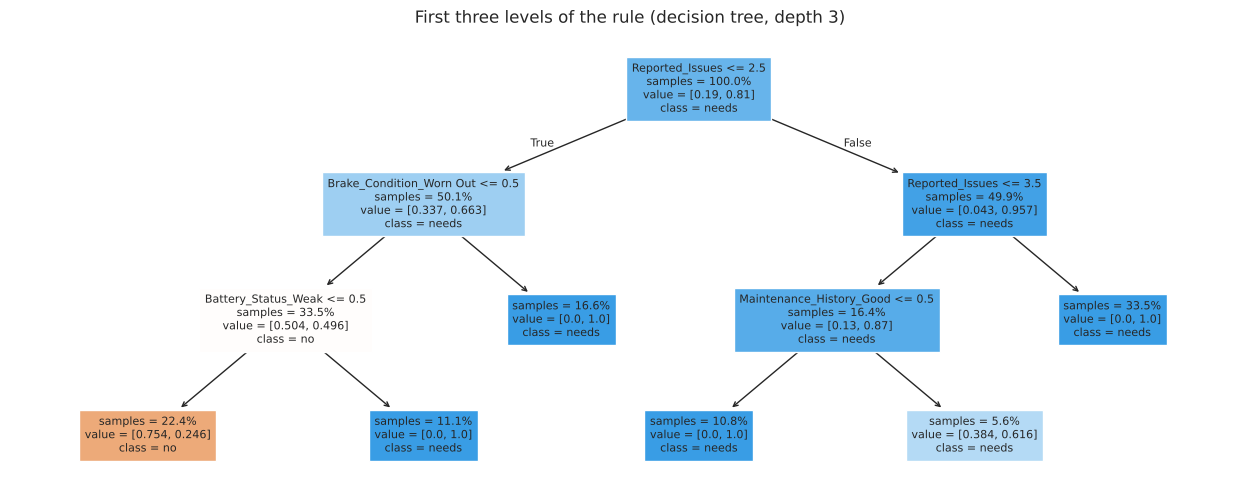

In [22]:
# A single, shallow decision tree shows the rule in readable form
rule_features = drivers
X_rule_train = pd.get_dummies(X_train[rule_features])
X_rule_test = pd.get_dummies(X_test[rule_features]).reindex(columns=X_rule_train.columns, fill_value=0)

for depth in [3, 5, 8, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE).fit(X_rule_train, y_train)
    print(f'Decision tree on the 6 driver attributes, max_depth={depth}: test accuracy = '
          f'{accuracy_score(y_test, tree.predict(X_rule_test)):.4f}')

small_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_rule_train, y_train)
plt.figure(figsize=(16, 6))
plot_tree(small_tree, feature_names=X_rule_train.columns, class_names=['no', 'needs'],
          filled=True, impurity=False, proportion=True, fontsize=8)
plt.title('First three levels of the rule (decision tree, depth 3)'); plt.show()

The permutation importances and the decision tree confirm the data-understanding finding: only the six driver attributes matter, and a single decision tree on these six attributes alone already reaches (almost) perfect accuracy. The label is a noise-free rule; Random Forest learns it, Logistic Regression cannot. **This is why the result should not be expected to transfer to real vehicle data**, where labels are noisy and depend on many more factors.

## 10. Cost analysis (assumed costs)

The error counts are measured on the test set; the costs are **assumptions** (a missed maintenance is assumed to be ten times more expensive than an unnecessary inspection), not real fleet data.

In [23]:
COST_FN, COST_FP = 500, 50   # assumed: missed maintenance, unnecessary inspection (EUR)
rows = []
for name, model in [('Logistic Regression', logreg), ('Random Forest', forest)]:
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test)).ravel()
    cost = COST_FN * fn + COST_FP * fp
    rows.append({'model': name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                 'total cost (EUR)': cost, 'cost per vehicle (EUR)': round(cost / len(y_test), 2)})
cost_table = pd.DataFrame(rows).set_index('model')
display(cost_table)
saving = cost_table['total cost (EUR)'].iloc[0] - cost_table['total cost (EUR)'].iloc[1]
print(f'Saving of Random Forest vs Logistic Regression: EUR {saving:,} on {len(y_test):,} test vehicles '
      f'(EUR {saving / len(y_test):.2f} per vehicle)')

,TN,FP,FN,TP,total cost (EUR),cost per vehicle (EUR)
model,,,,,,
Logistic Regression,1893,7,393,7707,196850,19.68
Random Forest,1900,0,0,8100,0,0.00


Saving of Random Forest vs Logistic Regression: EUR 196,850 on 10,000 test vehicles (EUR 19.68 per vehicle)


## 11. Export the same split for WEKA

To make the WEKA analysis comparable, we export exactly the same training and test records, with categories kept as text (WEKA treats them as nominal attributes) and the dates already converted to durations. In WEKA: open `weka_train.csv`, then *Test options → Supplied test set → `weka_test.csv`*.

In [24]:
train_out = X_train.assign(Need_Maintenance=y_train.map({0: 'no', 1: 'yes'}))
test_out = X_test.assign(Need_Maintenance=y_test.map({0: 'no', 1: 'yes'}))
train_out.to_csv('weka_train.csv', index=False)
test_out.to_csv('weka_test.csv', index=False)
print('Saved weka_train.csv', train_out.shape, 'and weka_test.csv', test_out.shape)

Saved weka_train.csv (40000, 20) and weka_test.csv (10000, 20)


## 12. Summary

1. **Data understanding:** 50,000 records, 20 columns, no missing values or duplicates, 81/19 class imbalance. The data shows clear signs of being synthetic (uniform distributions, mileage > odometer in 36% of rows), and the label is a deterministic rule of six attributes (battery, brakes, reported issues, maintenance history, service history, accident history).
2. **Correct evaluation:** stratified 80/20 split before any cleaning; all preprocessing fitted inside pipelines on training data only; model choices made with 5-fold cross-validation on the training set; the test set used once.
3. **Outliers:** Isolation Forest fitted on training features only flags 1% of the training records. They are rare but valid combinations, and removing them does not improve cross-validated performance, so the final models keep all training data.
4. **Results on the untouched test set (10,000 vehicles):** Random Forest 100% accuracy (ROC-AUC 1.00, no errors); Logistic Regression 96.0% accuracy (ROC-AUC 0.988), limited by its linear boundary (underfitting). Learning curves show no overfitting for Random Forest.
5. **Cost (assumed EUR 500 per missed maintenance, EUR 50 per false alarm):** Random Forest avoids EUR 196,850 of error costs on the test set compared with Logistic Regression, i.e. EUR 19.68 per vehicle.
6. **Limitations:** synthetic data with a noise-free rule, so the near-perfect score will not transfer to real vehicles; the costs are assumptions. Next step: validation on real, noisy fleet data.